In [64]:
import requests
import pandas as pd
import io
import matplotlib.pyplot as plt
import numpy as np

In [65]:
TXT_LINK_Y = "https://02427.compute.dtu.dk/material/exercises/lecture01_written_exercises/lecture01_kernel_methods_conditional_mean.txt"
# Download the y-values file from the provided link
response = requests.get(TXT_LINK_Y)
df = pd.read_csv(io.StringIO(response.text), sep=",", header=None, names=["y", "z"])

df.head()

,y,z
0,3.331332,10.852613
1,3.683827,13.764515
2,2.606120,6.502174
3,3.755309,14.020129
4,3.139244,9.638360


In [66]:

Y = df["y"].to_numpy()
Z = df["z"].to_numpy()

print("Y min:", Y.min())
print("Y max:", Y.max())
print(df[["y", "z"]].head())

Y min: 1.23075521411662
Y max: 4.38852192515965
          y          z
0  3.331332  10.852613
1  3.683827  13.764515
2  2.606120   6.502174
3  3.755309  14.020129
4  3.139244   9.638360


In [67]:
def k(u):
    """
    Simple box kernel:
    k(u) = 1 if |u| <= 1
           0 otherwise
    """
    return 1 if abs(u) <= 1 else 0


def approximate_conditional_mean(y, Y, Z, h):
    """
    Approximate:

        E[Z_t | Y_t = y]

    using

        sum k((y - Y_s)/h) * Z_s
        -------------------------
        sum k((y - Y_s)/h)
    """

    numerator = sum(
        k((y - Y_s) / h) * Z_s
        for Y_s, Z_s in zip(Y, Z)
    )

    denominator = sum(
        k((y - Y_s) / h)
        for Y_s in Y
    )

    return numerator / denominator



h = 0.1
y = 5

mean_estimate = approximate_conditional_mean(y, Y, Z, h)

print(mean_estimate)

nan


/tmp/ipykernel_12295/2308336715.py:33: RuntimeWarning: invalid value encountered in scalar divide
  return numerator / denominator


/tmp/ipykernel_12295/2308336715.py:33: RuntimeWarning: invalid value encountered in scalar divide
  return numerator / denominator


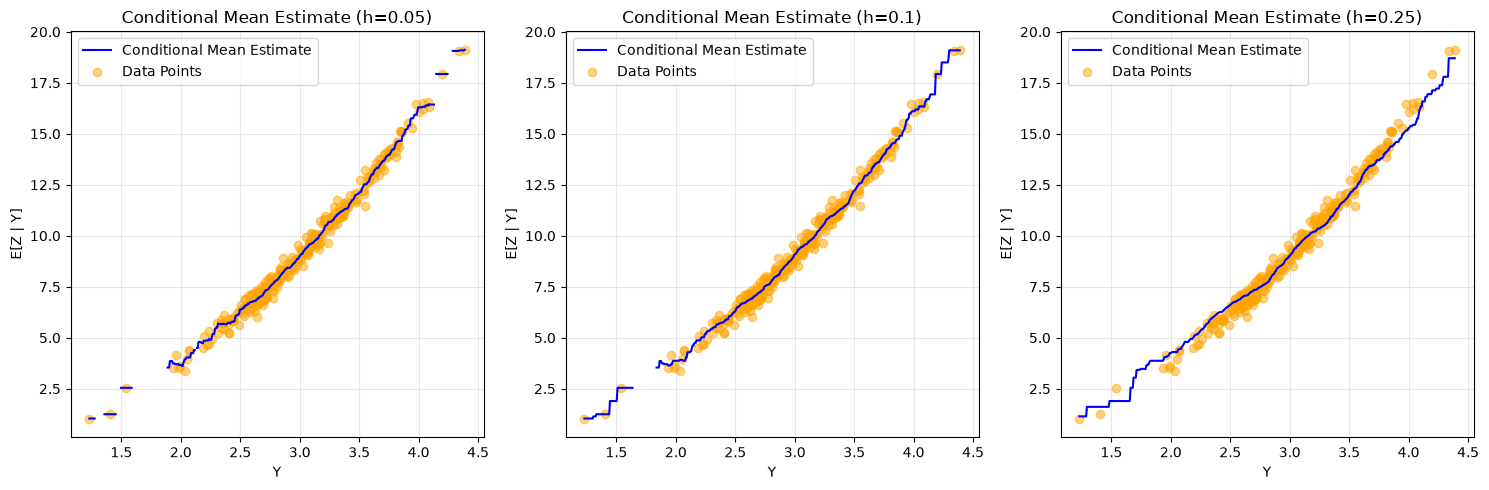

In [68]:
y_values = np.linspace(Y.min(), Y.max(), 500)
# Make 3 plots for different values of h
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
h_values = [0.05, 0.1, 0.25]

for idx, h_val in enumerate(h_values):
    mean_estimates_h = [approximate_conditional_mean(y, Y, Z, h_val) for y in y_values]
    
    axes[idx].plot(y_values, mean_estimates_h, label='Conditional Mean Estimate', color='blue')
    axes[idx].scatter(Y, Z, label='Data Points', color='orange', alpha=0.5)
    axes[idx].set_title(f'Conditional Mean Estimate (h={h_val})')
    axes[idx].set_xlabel('Y')
    axes[idx].set_ylabel('E[Z | Y]')
    axes[idx].legend()
    axes[idx].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np


def k(u):
    """
    Box kernel:

    k(u) = 1 if |u| <= 1
           0 otherwise
    """
    return 1 if abs(u) <= 1 else 0


def w_s(x, X_s, X, h):
    """
                         k(h^-1 (x - X_s))
    w_s(x) = -----------------------------------------
               (1/N) * sum_r k(h^-1 (x - X_r))
    """

    N = len(X)

    numerator = k((x - X_s) / h)

    denominator = (1 / N) * sum(
        k((x - X_r) / h)
        for X_r in X
    )

    return numerator / denominator


def theta_LS_hat(x, X, Y, h):
    """
                         sum_s w_s(x) Y_s
    theta_LS_hat(x) = -----------------------
                           sum_s w_s(x)
    """

    weights = [
        w_s(x, X_s, X, h)
        for X_s in X
    ]

    if np.isnan(weights).any():
        return np.nan

    numerator = sum(
        weight * Y_s
        for weight, Y_s in zip(weights, Y)
    )

    denominator = sum(weights)

    return numerator / denominator


def g_hat(x, X, Y, h):
    """
    From the slide:

    g_hat(x)
        = theta_LS_hat(x) * (1/N) * sum_s w_s(x)
        = theta_LS_hat(x)
    """

    N = len(X)

    weights = [
        w_s(x, X_s, X, h)
        for X_s in X
    ]

    if np.isnan(weights).any():
        return np.nan

    theta = theta_LS_hat(x, X, Y, h)

    normalization = (1 / N) * sum(weights)

    return theta * normalization

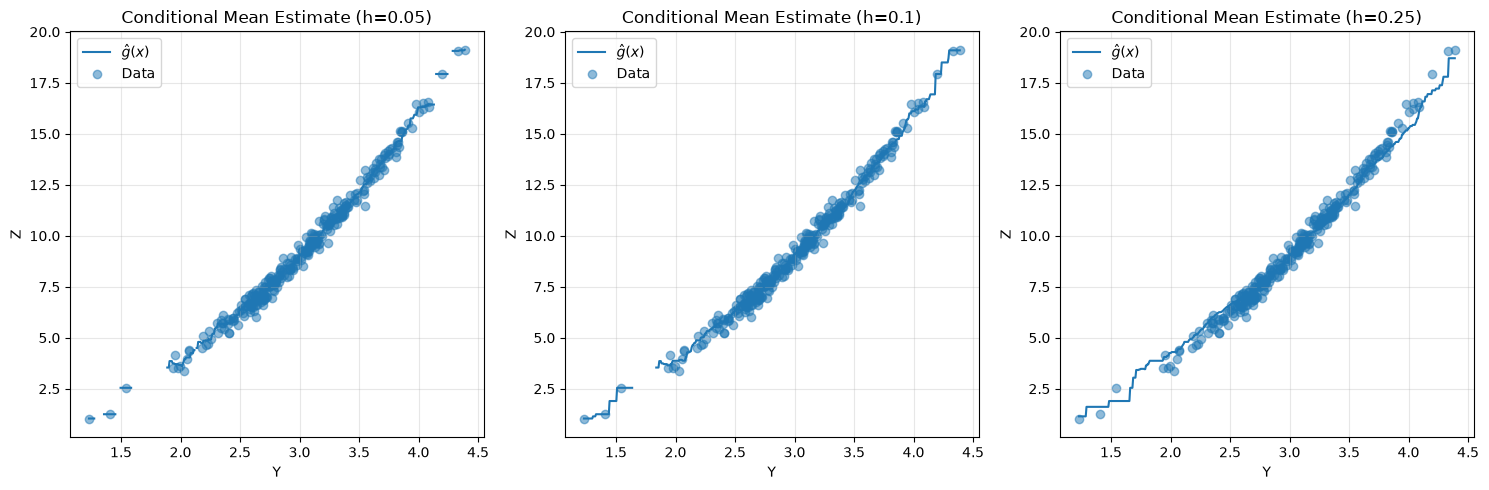

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

h_values = [0.05, 0.1, 0.25]

for idx, h_val in enumerate(h_values):

    # x-values where we estimate g_hat(x)
    x_vals = np.linspace(Y.min(), Y.max(), 500)

    # Estimate E[Z | Y = x]
    g_estimates = [
        g_hat(xi, Y, Z, h_val)
        for xi in x_vals
    ]

    # Estimated conditional mean
    axes[idx].plot(
        x_vals,
        g_estimates,
        label=r'$\hat{g}(x)$'
    )

    # Original observations
    axes[idx].scatter(
        Y,
        Z,
        label='Data',
        alpha=0.5
    )
 

    axes[idx].set_title(
        f'Conditional Mean Estimate (h={h_val})'
    )

    axes[idx].set_xlabel('Y')
    axes[idx].set_ylabel('Z')

    axes[idx].legend()
    axes[idx].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()
